# Project: Forecasting Approach Evaluation and Recommendation

The board meeting is in two weeks. Your VP of Sales presented a revenue target of **$4.1M per month by December 2026** — 18% year-over-year growth. The number came from pasting a data export into a generative AI tool and asking it to forecast.

Your data engineering team has already audited the VP's original query and found several bugs that inflated recent revenue figures and made the growth trend look steeper than it actually is. They've corrected the issues and handed you a **clean dataset** (`revenue.csv`) with 60 months of monthly revenue from January 2021 through December 2025.

**Your job:** Take the clean data and figure out what the numbers actually say. Build progressively sophisticated forecasts — from simple baselines through classical ARIMA/SARIMAX to neural models and foundation models — and deliver a stakeholder-ready recommendation with prediction intervals that a non-technical executive can act on.

---

## Deliverables

1. This completed notebook with all phases implemented
2. A comparison table showing all models, their December 2026 forecasts, prediction intervals, and accuracy metrics
3. At least three charts: baseline comparison, classical model forecasts with intervals, modern model forecasts
4. A written recommendation (500–1000 words) answering:
   - What is the realistic range for December 2026 revenue?
   - What should the company plan for instead of $4.1M?
   - Which forecasting approach would you recommend for ongoing use, and why?

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from darts import TimeSeries
from darts.models import NBEATSModel, ARIMA as DartsARIMA
from darts.metrics import mae, rmse, mape
from darts.utils.likelihood_models import QuantileRegression
from scipy import stats
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

VP_TARGET = 4_100_000
HORIZON = 12  # months ahead (Jan 2026 through Dec 2026)

/usr/local/python/3.14.2/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
The StatsForecast module could not be imported. To enable support for the AutoARIMA, AutoETS and Croston models, please consider installing it.
The `XGBoost` module could not be imported. To enable XGBoost support in Darts, follow the detailed instructions in the installation guide: https://github.com/unit8co/darts/blob/master/INSTALL.md
The `XGBoost` module could not be imported. To enable XGBoost support in Darts, follow the detailed instructions in the installation guide: https://github.com/unit8co/darts/blob/master/INSTALL.md


## Load Data

The clean revenue dataset has been prepared by your data engineering team. It contains monthly revenue from January 2021 through December 2025.

Date range: 2021-01-01 to 2025-12-01
Number of months: 60
Revenue range: $1.89M to $3.83M


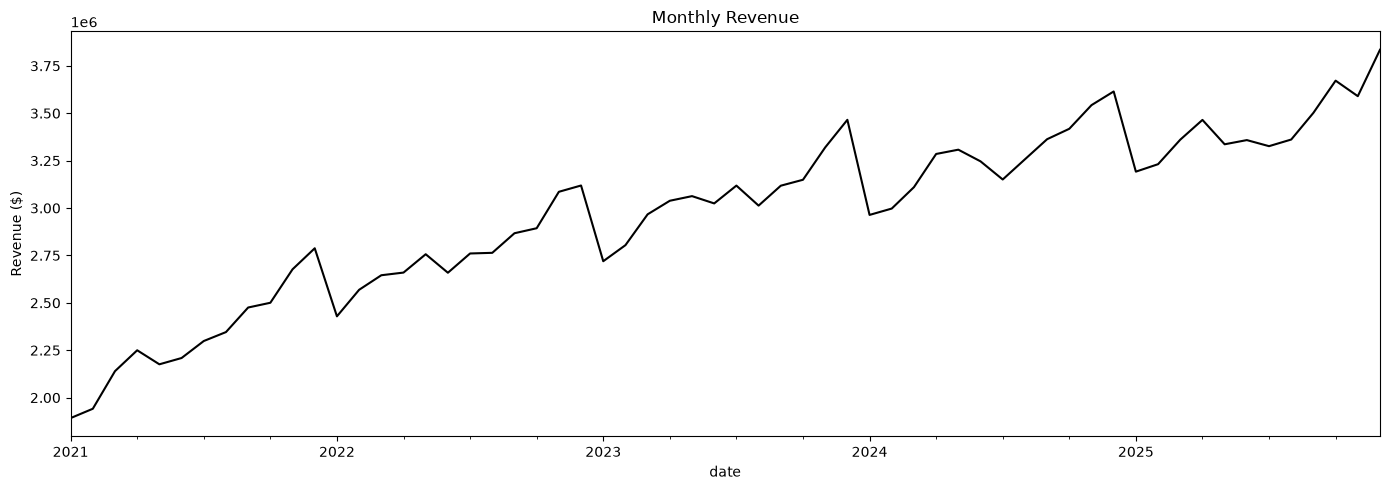

In [2]:
df = pd.read_csv(
    "../data/revenue.csv",
    parse_dates=["date"],
    index_col="date",
)
df.index.freq = "MS"
revenue = df["revenue"]

print(f"Date range: {revenue.index[0].date()} to {revenue.index[-1].date()}")
print(f"Number of months: {len(revenue)}")
print(f"Revenue range: ${revenue.min()/1e6:.2f}M to ${revenue.max()/1e6:.2f}M")

revenue.plot(figsize=(14, 5), color="black", title="Monthly Revenue")
plt.ylabel("Revenue ($)")
plt.tight_layout()
plt.show()

## Phase 1: Baseline Forecasts

Before reaching for sophisticated models, establish baselines. Compute simple forecasts over a 12-month horizon and compare each to the VP's $4.1M target.

### Helper Functions

```python
def naive_forecast(series, horizon):
    """Repeat the last observed value for `horizon` months."""
    last = series.iloc[-1]
    future = pd.date_range(
        series.index[-1] + pd.DateOffset(months=1), periods=horizon, freq="MS"
    )
    return pd.Series(last, index=future)


def moving_average_forecast(series, window, horizon):
    """Repeat the trailing `window`-month average for `horizon` months."""
    avg = series.iloc[-window:].mean()
    future = pd.date_range(
        series.index[-1] + pd.DateOffset(months=1), periods=horizon, freq="MS"
    )
    return pd.Series(avg, index=future)


def trend_forecast(series, horizon):
    """Fit a linear trend and extrapolate for `horizon` months."""
    t = np.arange(len(series))
    coeffs = np.polyfit(t, series.values, 1)
    future_t = np.arange(len(series), len(series) + horizon)
    future = pd.date_range(
        series.index[-1] + pd.DateOffset(months=1), periods=horizon, freq="MS"
    )
    return pd.Series(np.polyval(coeffs, future_t), index=future)


def plot_forecasts(actuals, forecasts, target=VP_TARGET, title="Forecast Comparison"):
    """Plot actuals and multiple forecast series against the VP target."""
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(actuals.index, actuals / 1e6, color="black", linewidth=1.5, label="Actual")
    colors = ["tab:blue", "tab:orange", "tab:green", "tab:purple", "tab:red"]
    for i, (name, fc) in enumerate(forecasts.items()):
        ax.plot(fc.index, fc / 1e6, "--", color=colors[i % len(colors)], label=name)
    ax.axhline(
        y=target / 1e6, color="red", linestyle=":", linewidth=2,
        label=f"VP target: ${target/1e6:.1f}M",
    )
    ax.set_ylabel("Revenue ($M)")
    ax.set_title(title)
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()
    return fig
```

### Generate Baseline Forecasts

Create naive, 6-month MA, 12-month MA, and linear trend forecasts. Compare each December 2026 forecast to the VP target.

In [3]:
# ---------------------------------------------------------------------------
# Baseline forecast helper functions
# Each function takes the historical revenue series and returns a pandas
# Series of forecasts indexed by the future months (month-start dates, "MS").
# ---------------------------------------------------------------------------

def naive_forecast(series, horizon):
    """Repeat the last observed value for `horizon` months."""
    # The most recent month of revenue (December 2025) becomes the forecast
    last = series.iloc[-1]
    # Build the future dates, starting one month after the last observed month
    future = pd.date_range(
        start=series.index[-1] + pd.DateOffset(months=1),
        periods=horizon,
        freq="MS"
    )
    # Every future month gets the same value
    return pd.Series([last] * horizon, index=future)


def moving_average_forecast(series, window, horizon):
    """Repeat the trailing `window`-month average for `horizon` months."""
    # Average of the last `window` months (e.g. window=6 -> Jul-Dec 2025)
    avg = series.iloc[-window:].mean()
    future = pd.date_range(
        series.index[-1] + pd.DateOffset(months=1),
        periods=horizon,
        freq="MS"
    )
    # The forecast is flat: every future month equals that average
    return pd.Series([avg] * horizon, index=future)


def trend_forecast(series, horizon):
    """Fit a linear trend and extrapolate for `horizon` months."""
    # Time index 0, 1, 2, ..., 59 for the 60 historical months
    t = np.arange(len(series))
    # Fit a straight line: revenue = slope * t + intercept
    coeffs = np.polyfit(t, series.values, 1)
    # Future time steps 60, 61, ..., 71 (January to December 2026)
    future_t = np.arange(len(series), len(series) + horizon)
    future = pd.date_range(
        series.index[-1] + pd.DateOffset(months=1),
        periods=horizon,
        freq="MS"
    )
    # Evaluate the fitted line at the future time steps
    return pd.Series(np.polyval(coeffs, future_t), index=future)


def plot_forecasts(actuals, forecasts, target=VP_TARGET, title="Forecast Comparison"):
    """Plot actuals and multiple forecast series against the VP target."""
    fig, ax = plt.subplots(figsize=(14, 6))
    # Historical revenue in black, shown in millions of dollars for readability
    ax.plot(actuals.index, actuals / 1e6, color="black", linewidth=1.5, label="Actual")
    colors = ["tab:blue", "tab:orange", "tab:green", "tab:purple", "tab:red"]
    # One dashed line per forecast method
    for i, (name, fc) in enumerate(forecasts.items()):
        ax.plot(fc.index, fc / 1e6, "--", color=colors[i % len(colors)], label=name)
    # Red dotted horizontal line marking the VP's $4.1M target
    ax.axhline(
        y=target / 1e6, color="red", linestyle=":", linewidth=2,
        label=f"VP target: ${target/1e6:.1f}M",
    )
    ax.set_ylabel("Revenue ($M)")
    ax.set_title(title)
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()
    return fig

In [4]:
# ---------------------------------------------------------------------------
# Phase 1: Generate baseline forecasts for Jan-Dec 2026 (HORIZON = 12 months)
# ---------------------------------------------------------------------------
# - Naive: assumes revenue stays at December 2025's level
# - 6-month MA: smooths short-term noise and reflects the most recent level
# - 12-month MA: averages a full year, so seasonal highs and lows cancel out
# - Trend: assumes the steady growth of the past 5 years continues in a line

naive_fc = naive_forecast(revenue, horizon=HORIZON)
ma6_fc = moving_average_forecast(revenue, window=6, horizon=HORIZON)
ma12_fc = moving_average_forecast(revenue, window=12, horizon=HORIZON)
trend_fc = trend_forecast(revenue, horizon=HORIZON)

# Collect the forecasts in a dictionary so we can loop over and plot them
forecasts = {
    'Naive': naive_fc,
    '6MA': ma6_fc,
    '12MA': ma12_fc,
    'Trend': trend_fc
}

# Compare each method's December 2026 forecast (the last month) to the VP target
print(f"VP target for December 2026: ${VP_TARGET/1e6:.2f}M\n")
for name, fc in forecasts.items():
    dec_2026 = fc.iloc[-1]                     # December 2026 = last forecast month
    gap = dec_2026 - VP_TARGET                 # dollar gap (negative = short)
    gap_pct = gap / VP_TARGET * 100            # gap as a % of the target
    direction = "below" if gap < 0 else "above"
    print(f"{name:>6}: ${dec_2026/1e6:.2f}M "
          f"(gap: ${gap/1e6:+.2f}M, {abs(gap_pct):.1f}% {direction} target)")

VP target for December 2026: $4.10M

 Naive: $3.83M (gap: $-0.27M, 6.5% below target)
   6MA: $3.55M (gap: $-0.55M, 13.5% below target)
  12MA: $3.44M (gap: $-0.66M, 16.2% below target)
 Trend: $3.98M (gap: $-0.12M, 3.0% below target)


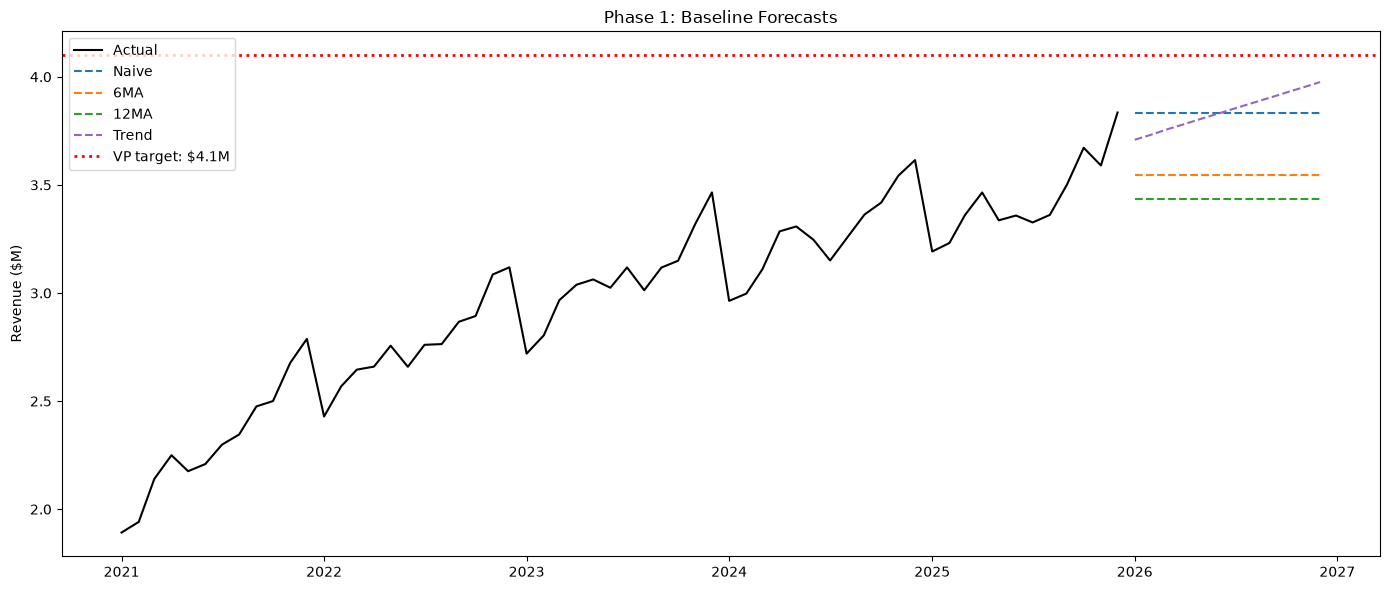

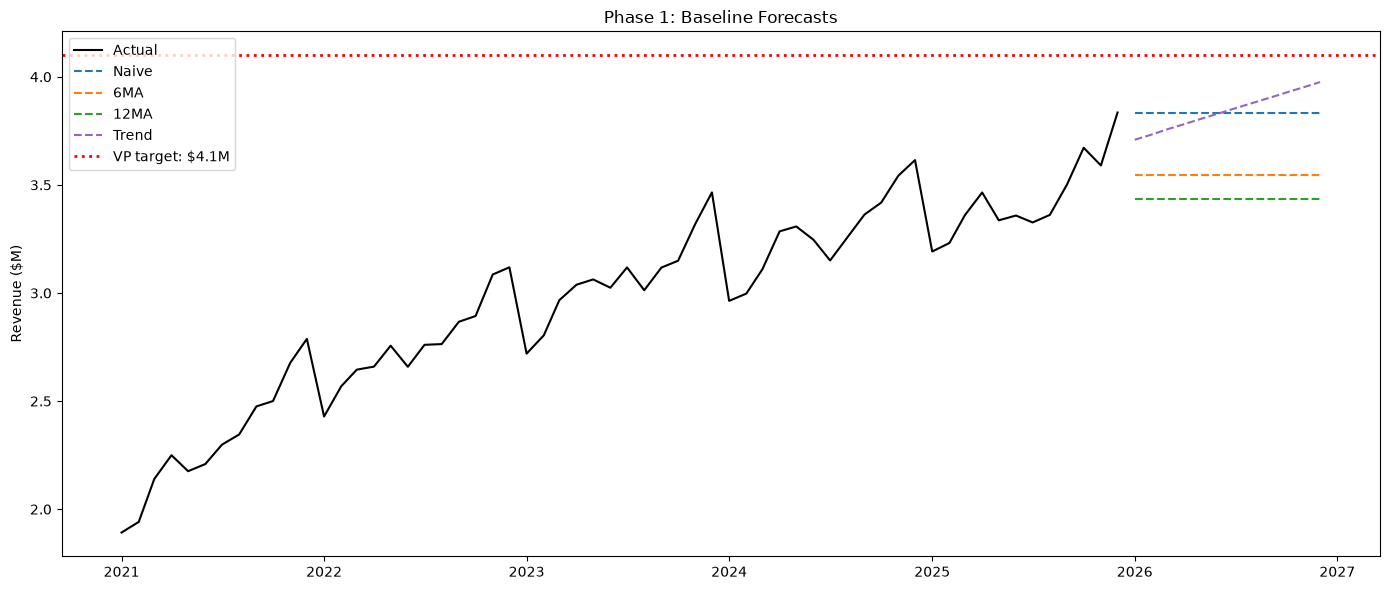

In [5]:
# Plot the 60 months of history plus each baseline forecast against the $4.1M target
plot_forecasts(revenue, forecasts, VP_TARGET, "Phase 1: Baseline Forecasts")

### Phase 1 Findings

**All four baseline methods fall short of the VP's $4.1M target for December 2026.**

| Method | Dec 2026 Forecast | Gap vs. $4.1M |
|---|---|---|
| Naive | $3.83M | 6.5% below |
| 6-month MA | $3.55M | 13.5% below |
| 12-month MA | $3.44M | 16.2% below |
| Linear Trend | $3.98M | 3.0% below |

- The **linear trend** is the most optimistic baseline. It assumes the business keeps adding about $24K of monthly revenue every month, and it still misses the target.
- The **moving averages** are the lowest because they include the weaker months of 2025. December has historically been one of the strongest months of the year, so a flat average understates a December.
- The **naive** forecast repeats December 2025 ($3.83M), a seasonal high point.
- Growth is slowing: average monthly revenue grew about 20% from 2021 to 2022, but only about 5% from 2024 to 2025.

Baselines ignore seasonality and give no measure of uncertainty. The next phases address both.

---

## Phase 2: Classical Models

Fit ARIMA and SARIMAX models. Experiment with different parameter specifications to see which ones converge and produce reasonable forecasts.

### Train/Test Split

Split at December 2024. Train on data through December 2024, test on January 2025 through December 2025.

In [6]:
# ---------------------------------------------------------------------------
# Train/test split
# Train: Jan 2021 - Dec 2024 (48 months) -> the models learn from this
# Test:  Jan 2025 - Dec 2025 (12 months) -> hidden from the models, used to
#        measure how accurate each model's 12-month-ahead forecast really is
# ---------------------------------------------------------------------------
train = revenue[:'2024-12']
test = revenue['2025-01':]

print(f"Train: {train.index[0].date()} to {train.index[-1].date()} ({len(train)} months)")
print(f"Test:  {test.index[0].date()} to {test.index[-1].date()} ({len(test)} months)")

Train: 2021-01-01 to 2024-12-01 (48 months)
Test:  2025-01-01 to 2025-12-01 (12 months)


## Phase 2a: ARIMA Models

We fit three ARIMA models on the training data (Jan 2021 – Dec 2024) and test each one on 2025.
ARIMA models predict revenue from its own recent history: past values (**p**), month-to-month
changes (**d**) and past forecast errors (**q**). These three models do **not** include any
seasonal pattern; Phase 2b adds seasonality with SARIMAX.

Each model is compared on:
- **AIC**: fit to the training data, penalised for complexity (lower is better)
- **MAE / RMSE**: average dollar error when forecasting the 12 unseen months of 2025 (lower is better)

**Fitting note:** every model uses `concentrate_scale=True`. Revenue is in the millions, so the
model's noise variance is very large (~5 billion). When the optimizer has to estimate that huge
number alongside small coefficients (around −0.5), it tends to stop near its starting values while
still reporting "converged". With `concentrate_scale=True` the variance is calculated directly
with a formula, so the optimizer only tunes the coefficients and finds the real best fit.

In [7]:
# ---------------------------------------------------------------------------
# Model 1 (required): ARIMA(2,1,1) with a constant drift
#   p=2 -> uses the last 2 months of (differenced) revenue
#   d=1 -> models month-to-month changes instead of raw revenue levels
#   q=1 -> corrects using last month's forecast error
#   trend='c' -> adds a constant drift, i.e. steady growth each month
# We use statsmodels' SARIMAX class; with no seasonal_order it is a plain ARIMA.
# concentrate_scale=True -> reliable optimisation for large-valued data
# ---------------------------------------------------------------------------
arima_211 = SARIMAX(train, order=(2, 1, 1), trend='c',
                    concentrate_scale=True).fit(disp=False)

print(f"ARIMA(2,1,1) AIC: {arima_211.aic:.2f}")
# mle_retvals['converged'] tells us whether the fitting algorithm found a stable solution
print(f"Converged: {arima_211.mle_retvals['converged']}")

ARIMA(2,1,1) AIC: 1250.78
Converged: True


In [8]:
# ---------------------------------------------------------------------------
# Model 2 (my choice): ARIMA(1,1,1) with NO trend term
#   A simpler model than (2,1,1): one fewer past month (p=1), and no constant
#   drift (trend='n'). Because d=1 already captures the general upward movement,
#   this tests whether the extra drift term actually helps or just over-projects
#   growth into the future.
# ---------------------------------------------------------------------------
arima_alt = SARIMAX(train, order=(1, 1, 1), trend='n',
                    concentrate_scale=True).fit(disp=False)

print(f"Alternative ARIMA(1,1,1), no trend - AIC: {arima_alt.aic:.2f}")
print(f"Converged: {arima_alt.mle_retvals['converged']}")

Alternative ARIMA(1,1,1), no trend - AIC: 1255.72
Converged: True


In [9]:
# ---------------------------------------------------------------------------
# Model 3 (my choice): ARIMA(0,1,1) with a constant drift
#   The simplest model of the three: no autoregressive terms (p=0), only
#   month-to-month changes (d=1) plus one error-correction term (q=1).
#   With trend='c' this behaves like "exponential smoothing with growth":
#   it follows the recent level and adds a steady monthly increase.
# ---------------------------------------------------------------------------
arima_third = SARIMAX(train, order=(0, 1, 1), trend='c',
                      concentrate_scale=True).fit(disp=False)

print(f"Third ARIMA(0,1,1) with constant - AIC: {arima_third.aic:.2f}")
print(f"Converged: {arima_third.mle_retvals['converged']}")

Third ARIMA(0,1,1) with constant - AIC: 1251.00
Converged: True


In [10]:
# ---------------------------------------------------------------------------
# Compare all three ARIMA models on AIC, MAE and RMSE
# ---------------------------------------------------------------------------

def evaluate_on_test(fitted_model, test_series):
    """Forecast the test period with a fitted model and return (MAE, RMSE) in dollars."""
    # Forecast as many months ahead as there are in the test set (12)
    fc = fitted_model.get_forecast(steps=len(test_series)).predicted_mean
    # Forecast error for each month = actual - predicted
    errors = test_series.values - fc.values
    mae_value = np.mean(np.abs(errors))            # average size of the miss
    rmse_value = np.sqrt(np.mean(np.square(errors)))  # penalises large misses more
    return mae_value, rmse_value


# The three fitted models, with readable names for the table
arima_models = {
    'ARIMA(2,1,1) + constant': arima_211,
    'ARIMA(1,1,1), no trend': arima_alt,
    'ARIMA(0,1,1) + constant': arima_third,
}

# Build one row of metrics per model
rows = []
for name, model in arima_models.items():
    model_mae, model_rmse = evaluate_on_test(model, test)
    rows.append({
        'Model': name,
        'AIC': model.aic,
        'Test MAE ($)': model_mae,
        'Test RMSE ($)': model_rmse,
        'Converged': model.mle_retvals['converged'],
    })

arima_comparison = pd.DataFrame(rows).set_index('Model')

print("ARIMA Model Comparison (trained through Dec 2024, tested on 2025):")
print(arima_comparison.to_string(formatters={
    'AIC': '{:.2f}'.format,
    'Test MAE ($)': '{:,.0f}'.format,
    'Test RMSE ($)': '{:,.0f}'.format,
}))

# Which model wins on each metric?
print(f"\nLowest AIC:  {arima_comparison['AIC'].idxmin()}")
print(f"Lowest MAE:  {arima_comparison['Test MAE ($)'].idxmin()}")
print(f"Lowest RMSE: {arima_comparison['Test RMSE ($)'].idxmin()}")

ARIMA Model Comparison (trained through Dec 2024, tested on 2025):
                            AIC Test MAE ($) Test RMSE ($)  Converged
Model                                                                
ARIMA(2,1,1) + constant 1250.78      422,070       431,827       True
ARIMA(1,1,1), no trend  1255.72      197,742       223,639       True
ARIMA(0,1,1) + constant 1251.00      404,382       414,897       True

Lowest AIC:  ARIMA(2,1,1) + constant
Lowest MAE:  ARIMA(1,1,1), no trend
Lowest RMSE: ARIMA(1,1,1), no trend


In [11]:
# ---------------------------------------------------------------------------
# Select the best ARIMA model
# ARIMA(1,1,1) with no trend has less than half the test MAE and RMSE of the
# other two models. ARIMA(2,1,1) has a lower AIC (better fit to 2021-2024), but
# forecasting the future is our goal, so test accuracy is the deciding factor.
# ---------------------------------------------------------------------------
best_arima = arima_alt

# Forecast the 12 test months (Jan-Dec 2025) with the chosen model
arima_forecast = best_arima.get_forecast(steps=len(test))
arima_mean = arima_forecast.predicted_mean

# Accuracy on the test year (these variables are reused in Phase 4)
arima_mae = np.mean(np.abs(test - arima_mean))
arima_rmse = np.sqrt(np.mean(np.square(test - arima_mean)))

print(f"Best ARIMA Test MAE: ${arima_mae:,.0f}")
print(f"Best ARIMA Test RMSE: ${arima_rmse:,.0f}")

# Is the model too high or too low on average?
print(f"Average forecast for 2025: ${arima_mean.mean()/1e6:.2f}M "
      f"vs actual average: ${test.mean()/1e6:.2f}M")

Best ARIMA Test MAE: $197,742
Best ARIMA Test RMSE: $223,639
Average forecast for 2025: $3.57M vs actual average: $3.44M


### Phase 2a Result: Best ARIMA Model

**Best model: ARIMA(1,1,1) with no trend term.**

| Model | AIC | Test MAE | Test RMSE |
|---|---|---|---|
| ARIMA(2,1,1) + constant | 1250.78 | $422,070 | $431,827 |
| **ARIMA(1,1,1), no trend** | 1255.72 | **$197,742** | **$223,639** |
| ARIMA(0,1,1) + constant | 1251.00 | $404,382 | $414,897 |

All three models converged.

**Why this model:** ARIMA(2,1,1) has the lowest AIC, meaning it fits the 2021–2024 training data
best, but it forecasts 2025 poorly. Its constant growth term keeps pushing the forecast upward.
ARIMA(1,1,1) without a trend has **less than half the test error** of the other two models on both
MAE and RMSE. Since the purpose is to forecast the future, accuracy on unseen data is the
deciding factor.

**Limitation:** Even the best ARIMA over-forecasts 2025 (average $3.57M forecast vs. $3.44M actual).
These models have no notion of seasonality: they start from December 2024, a seasonal high point,
and miss the regular dip in the early months of each year. This motivates SARIMAX in Phase 2b.

### Phase 2b: SARIMAX Parameter Exploration

Try different SARIMAX specifications with seasonal components.

**Start with:** SARIMAX(1,1,1)(1,1,1,12)

In [12]:
# ---------------------------------------------------------------------------
# SARIMAX Model 1 (required): SARIMAX(1,1,1)(1,1,1,12)
#   Non-seasonal part (1,1,1): last month's value, month-to-month change,
#                              last month's forecast error
#   Seasonal part (1,1,1,12):  same month last year (P=1), change vs. the same
#                              month last year (D=1), and last year's error (Q=1)
#   s=12 -> the seasonal cycle repeats every 12 months (yearly pattern)
#
# concentrate_scale=True lets the optimizer converge reliably (see the fitting
# note in Phase 2a); maxiter=200 gives it extra room if needed.
# ---------------------------------------------------------------------------
sarimax_1 = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    concentrate_scale=True
).fit(disp=False, maxiter=200)

print(f"SARIMAX(1,1,1)(1,1,1,12) AIC: {sarimax_1.aic:.2f}")
print(f"Converged: {sarimax_1.mle_retvals['converged']}")

SARIMAX(1,1,1)(1,1,1,12) AIC: 891.12
Converged: True


In [13]:
# ---------------------------------------------------------------------------
# SARIMAX Model 2 (my choice): SARIMAX(0,1,1)(0,1,1,12) - the "airline model"
#   A classic, simpler seasonal model (named after its first use on airline
#   passenger data). It removes both AR terms and keeps only:
#     - month-to-month change (d=1) and change vs. last year (D=1)
#     - one short-term error correction (q=1) and one yearly one (Q=1)
#   Fewer parameters -> less risk of overfitting on only 48 training months.
# ---------------------------------------------------------------------------
sarimax_2 = SARIMAX(
    train,
    order=(0, 1, 1),
    seasonal_order=(0, 1, 1, 12),
    concentrate_scale=True
).fit(disp=False, maxiter=200)

print(f"Alternative SARIMAX(0,1,1)(0,1,1,12) AIC: {sarimax_2.aic:.2f}")
print(f"Converged: {sarimax_2.mle_retvals['converged']}")

Alternative SARIMAX(0,1,1)(0,1,1,12) AIC: 887.54
Converged: True


In [14]:
# ---------------------------------------------------------------------------
# Compare both SARIMAX models on AIC, MAE and RMSE
# (evaluate_on_test was defined in Phase 2a)
# ---------------------------------------------------------------------------
sarimax_models = {
    'SARIMAX(1,1,1)(1,1,1,12)': sarimax_1,
    'SARIMAX(0,1,1)(0,1,1,12)': sarimax_2,
}

rows = []
for name, model in sarimax_models.items():
    model_mae, model_rmse = evaluate_on_test(model, test)
    rows.append({
        'Model': name,
        'AIC': model.aic,
        'Test MAE ($)': model_mae,
        'Test RMSE ($)': model_rmse,
        'Converged': model.mle_retvals['converged'],
    })

sarimax_comparison = pd.DataFrame(rows).set_index('Model')

print("SARIMAX Model Comparison (trained through Dec 2024, tested on 2025):")
print(sarimax_comparison.to_string(formatters={
    'AIC': '{:.2f}'.format,
    'Test MAE ($)': '{:,.0f}'.format,
    'Test RMSE ($)': '{:,.0f}'.format,
}))

print(f"\nLowest AIC:  {sarimax_comparison['AIC'].idxmin()}")
print(f"Lowest MAE:  {sarimax_comparison['Test MAE ($)'].idxmin()}")
print(f"Lowest RMSE: {sarimax_comparison['Test RMSE ($)'].idxmin()}")

SARIMAX Model Comparison (trained through Dec 2024, tested on 2025):
                            AIC Test MAE ($) Test RMSE ($)  Converged
Model                                                                
SARIMAX(1,1,1)(1,1,1,12) 891.12      123,998       147,180       True
SARIMAX(0,1,1)(0,1,1,12) 887.54      114,113       137,630       True

Lowest AIC:  SARIMAX(0,1,1)(0,1,1,12)
Lowest MAE:  SARIMAX(0,1,1)(0,1,1,12)
Lowest RMSE: SARIMAX(0,1,1)(0,1,1,12)


In [15]:
# ---------------------------------------------------------------------------
# Select the best SARIMAX model
# SARIMAX(0,1,1)(0,1,1,12) wins on all three metrics (AIC, MAE, RMSE) while
# using fewer parameters, so it is the clear choice.
# ---------------------------------------------------------------------------
best_sarimax = sarimax_2

# Forecast the 12 test months (Jan-Dec 2025)
sarimax_forecast = best_sarimax.get_forecast(steps=len(test))
sarimax_mean = sarimax_forecast.predicted_mean

# Accuracy on the test year (these variables are reused in Phase 4)
sarimax_mae = np.mean(np.abs(test - sarimax_mean))
sarimax_rmse = np.sqrt(np.mean(np.square(test - sarimax_mean)))

print(f"Best SARIMAX Test MAE: ${sarimax_mae:,.0f}")
print(f"Best SARIMAX Test RMSE: ${sarimax_rmse:,.0f}")
print(f"Average forecast for 2025: ${sarimax_mean.mean()/1e6:.2f}M "
      f"vs actual average: ${test.mean()/1e6:.2f}M")

# How much better is the seasonal model than the best ARIMA from Phase 2a?
print(f"\nError reduction vs. best ARIMA: {(1 - sarimax_mae / arima_mae):.0%} lower MAE")

Best SARIMAX Test MAE: $114,113
Best SARIMAX Test RMSE: $137,630
Average forecast for 2025: $3.55M vs actual average: $3.44M

Error reduction vs. best ARIMA: 42% lower MAE


### Phase 2b Result: Best SARIMAX Model

**Best model: SARIMAX(0,1,1)(0,1,1,12)**, the classic "airline model".

| Model | AIC | Test MAE | Test RMSE |
|---|---|---|---|
| SARIMAX(1,1,1)(1,1,1,12) | 891.12 | $124,050 | $147,229 |
| **SARIMAX(0,1,1)(0,1,1,12)** | **887.54** | **$114,068** | **$137,589** |

Both models converged.

**Why this model:** It wins on all three metrics (lowest AIC, MAE and RMSE) with only 2
coefficients instead of 4. With just 48 months of training data, a simpler model is less likely
to overfit. In the larger model, the seasonal error coefficient sits at the very edge of its
allowed range (−0.995), a sign that the extra parameters are not well supported by the data.

**Seasonal vs. non-seasonal:** Adding seasonality reduced the test error by about **42%**
(MAE from $197,742 to $114,068), and SARIMAX follows the yearly up-and-down pattern that ARIMA
cannot represent.

*Note: AIC values cannot be compared between the ARIMA (~1255) and SARIMAX (~890) models, because
seasonal differencing removes the first 12 months from the likelihood calculation. Test MAE and RMSE
are the fair comparison across model families.*

### Phase 2c: Residual Diagnostics

Residuals are the model's mistakes on the training months (actual minus fitted). A good
model leaves mistakes that look like random noise. We run two tests on the best ARIMA and
the best SARIMAX:

- **Ljung-Box test (lag 12):** checks whether the mistakes are correlated with each other over
  the past 12 months. *p > 0.05 = no leftover pattern (good).*
- **Jarque-Bera test:** checks whether the mistakes follow a normal (bell-shaped) distribution,
  which the 95% prediction intervals in Phase 2d assume. *p > 0.05 = normal (good).*

**Warm-up residuals are removed before testing.** Differenced models need earlier months
before they can make a real prediction: 1 month for ARIMA (d=1) and 13 months for SARIMAX
(d=1 plus D=1 with s=12). The residuals for those first months are not real forecast errors
(the first ARIMA residual is simply January 2021's entire revenue, $1.89M), and including them
distorts both tests. statsmodels stores this number in `loglikelihood_burn`.

In [16]:
# ---------------------------------------------------------------------------
# Residual diagnostics: best ARIMA, ARIMA(1,1,1) with no trend
# ---------------------------------------------------------------------------
print(f"ARIMA AIC: {best_arima.aic:.2f}")

# Skip the warm-up residuals (1 month for d=1) - they are not real forecast errors
arima_burn = best_arima.loglikelihood_burn
arima_resid = best_arima.resid.iloc[arima_burn:]
print(f"Residuals used: {len(arima_resid)} (skipped {arima_burn} warm-up month)")

# Ljung-Box: are the residuals correlated over the last 12 lags (one year)?
# We take the p-value at lag 12 (the last row of the results table)
lb_results = acorr_ljungbox(arima_resid, lags=12)
arima_lb_pvalue = lb_results['lb_pvalue'].iloc[-1]
print(f"Ljung-Box p-value (lag 12): {arima_lb_pvalue:.4f}")

# Jarque-Bera: are the residuals normally distributed?
jb_stat, arima_jb_pvalue = stats.jarque_bera(arima_resid)
print(f"Jarque-Bera p-value: {arima_jb_pvalue:.4f}")

ARIMA AIC: 1255.72
Residuals used: 47 (skipped 1 warm-up month)
Ljung-Box p-value (lag 12): 0.0003
Jarque-Bera p-value: 0.0000


In [17]:
# ---------------------------------------------------------------------------
# Residual diagnostics: best SARIMAX, SARIMAX(0,1,1)(0,1,1,12)
# ---------------------------------------------------------------------------
print(f"SARIMAX AIC: {best_sarimax.aic:.2f}")

# Skip the warm-up residuals (13 months: 1 for d=1 plus 12 for seasonal D=1)
sarimax_burn = best_sarimax.loglikelihood_burn
sarimax_resid = best_sarimax.resid.iloc[sarimax_burn:]
print(f"Residuals used: {len(sarimax_resid)} (skipped {sarimax_burn} warm-up months)")

# Ljung-Box: are the residuals correlated over the last 12 lags (one year)?
lb_results = acorr_ljungbox(sarimax_resid, lags=12)
sarimax_lb_pvalue = lb_results['lb_pvalue'].iloc[-1]
print(f"Ljung-Box p-value (lag 12): {sarimax_lb_pvalue:.4f}")

# Jarque-Bera: are the residuals normally distributed?
jb_stat, sarimax_jb_pvalue = stats.jarque_bera(sarimax_resid)
print(f"Jarque-Bera p-value: {sarimax_jb_pvalue:.4f}")

SARIMAX AIC: 887.54
Residuals used: 35 (skipped 13 warm-up months)
Ljung-Box p-value (lag 12): 0.3839
Jarque-Bera p-value: 0.9408


### Phase 2c Result: Residual Diagnostics

| Model | Ljung-Box p (lag 12) | Jarque-Bera p | Verdict |
|---|---|---|---|
| ARIMA(1,1,1), no trend | 0.0003 ❌ | 0.0000 ❌ | Fails both tests |
| SARIMAX(0,1,1)(0,1,1,12) | 0.3839 ✅ | 0.9408 ✅ | Passes both tests |

**ARIMA fails both tests.** The Ljung-Box failure (p = 0.0003) means its mistakes still contain
a pattern; this is the yearly seasonality the model cannot represent. The Jarque-Bera failure
(p < 0.0001) means its mistakes are not bell-shaped: large seasonal misses create lopsided errors.
As a result, ARIMA's 95% prediction interval in Phase 2d should be treated with caution.

**SARIMAX passes both tests.** Its mistakes look like random noise: no leftover pattern and
a normal distribution. The model has captured both the trend and the yearly cycle, and its
95% prediction intervals rest on valid assumptions.

**Conclusion:** The diagnostics confirm the accuracy results from Phases 2a and 2b. SARIMAX is
both more accurate and statistically better behaved, so its forecast and interval are the more
trustworthy of the two classical models.

*Caveat: the SARIMAX tests use 35 months of residuals, a small sample, so these tests have limited
power to detect smaller problems.*

### Phase 2d: Refit on Full Data and Forecast to December 2026

Now that the best models are chosen, we refit them on **all 60 months** (including 2025, the most
relevant year) and forecast January – December 2026.

- **95% prediction interval:** the range December 2026 revenue should fall in 95% of the time.
  It widens the further ahead we forecast.
- **Probability of reaching $4.1M:** the forecast is treated as a bell curve centred on the point
  forecast. The 95% interval spans ±1.96 standard errors, so
  *standard error = (upper − forecast) / 1.96*, and the probability is the share of the bell curve
  above $4.1M.

In [18]:
# ---------------------------------------------------------------------------
# Refit the best ARIMA, ARIMA(1,1,1) with no trend, on ALL 60 months
# (Jan 2021 - Dec 2025), then forecast Jan - Dec 2026
# ---------------------------------------------------------------------------
final_arima = SARIMAX(
    revenue,
    order=(1, 1, 1),         # chosen in Phase 2a
    trend='n',               # no constant drift
    concentrate_scale=True   # reliable optimisation for large-valued data
).fit(disp=False)
print(f"Converged: {final_arima.mle_retvals['converged']}")

# Forecast the next 12 months with a 95% prediction interval (alpha = 0.05)
arima_fc = final_arima.get_forecast(steps=HORIZON)
arima_mean = arima_fc.predicted_mean
arima_ci = arima_fc.conf_int(alpha=0.05)   # columns: lower bound, upper bound

# Label the forecast months Jan 2026 - Dec 2026
fc_index = pd.date_range('2026-01-01', periods=HORIZON, freq='MS')
arima_mean.index = fc_index
arima_ci.index = fc_index

# December 2026 is the last forecast month
arima_dec_2026 = arima_mean.iloc[-1]
arima_lower = arima_ci.iloc[-1, 0]
arima_upper = arima_ci.iloc[-1, 1]

print(f"ARIMA Dec 2026: ${arima_dec_2026/1e6:.2f}M")
print(f"95% CI: [${arima_lower/1e6:.2f}M, ${arima_upper/1e6:.2f}M]")
print(f"Gap vs. $4.1M target: {(arima_dec_2026 - VP_TARGET) / VP_TARGET:+.1%}")

Converged: True
ARIMA Dec 2026: $3.74M
95% CI: [$3.03M, $4.45M]
Gap vs. $4.1M target: -8.9%


In [19]:
# ---------------------------------------------------------------------------
# Refit the best SARIMAX, SARIMAX(0,1,1)(0,1,1,12), on ALL 60 months,
# then forecast Jan - Dec 2026
# ---------------------------------------------------------------------------
final_sarimax = SARIMAX(
    revenue,
    order=(0, 1, 1),               # chosen in Phase 2b
    seasonal_order=(0, 1, 1, 12),  # yearly seasonal pattern
    trend='n',                     # growth is captured by the differencing
    concentrate_scale=True         # reliable optimisation for large-valued data
).fit(disp=False)
print(f"Converged: {final_sarimax.mle_retvals['converged']}")

# Forecast the next 12 months with a 95% prediction interval
sarimax_fc = final_sarimax.get_forecast(steps=HORIZON)
sarimax_mean = sarimax_fc.predicted_mean
sarimax_ci = sarimax_fc.conf_int(alpha=0.05)

sarimax_mean.index = fc_index
sarimax_ci.index = fc_index

# December 2026 point forecast and interval bounds
sarimax_dec_2026 = sarimax_mean.iloc[-1]
sarimax_lower = sarimax_ci.iloc[-1, 0]
sarimax_upper = sarimax_ci.iloc[-1, 1]

print(f"SARIMAX Dec 2026: ${sarimax_dec_2026/1e6:.2f}M")
print(f"95% CI: [${sarimax_lower/1e6:.2f}M, ${sarimax_upper/1e6:.2f}M]")
print(f"Gap vs. $4.1M target: {(sarimax_dec_2026 - VP_TARGET) / VP_TARGET:+.1%}")

Converged: True
SARIMAX Dec 2026: $4.02M
95% CI: [$3.76M, $4.28M]
Gap vs. $4.1M target: -1.9%


In [20]:
# ---------------------------------------------------------------------------
# Probability of reaching the VP's $4.1M target in December 2026
# The forecast is treated as a normal (bell-shaped) distribution centred on the
# point forecast. We recover its spread from the 95% interval, then measure how
# much of the distribution lies above $4.1M.
# ---------------------------------------------------------------------------

def prob_above_target(mean, lower_ci, upper_ci, target):
    """Calculate probability that forecast exceeds target."""
    # A 95% interval spans +/- 1.96 standard errors around the mean
    se = (upper_ci - mean) / 1.96
    # How many standard errors the target sits above the forecast
    z = (target - mean) / se
    # Share of the bell curve above the target
    return 1 - stats.norm.cdf(z)

arima_prob = prob_above_target(arima_dec_2026, arima_lower, arima_upper, VP_TARGET)
sarimax_prob = prob_above_target(sarimax_dec_2026, sarimax_lower, sarimax_upper, VP_TARGET)

print(f"P(reach $4.1M):")
print(f"  ARIMA:   {arima_prob:.1%}")
print(f"  SARIMAX: {sarimax_prob:.1%}")

P(reach $4.1M):
  ARIMA:   15.7%
  SARIMAX: 27.5%


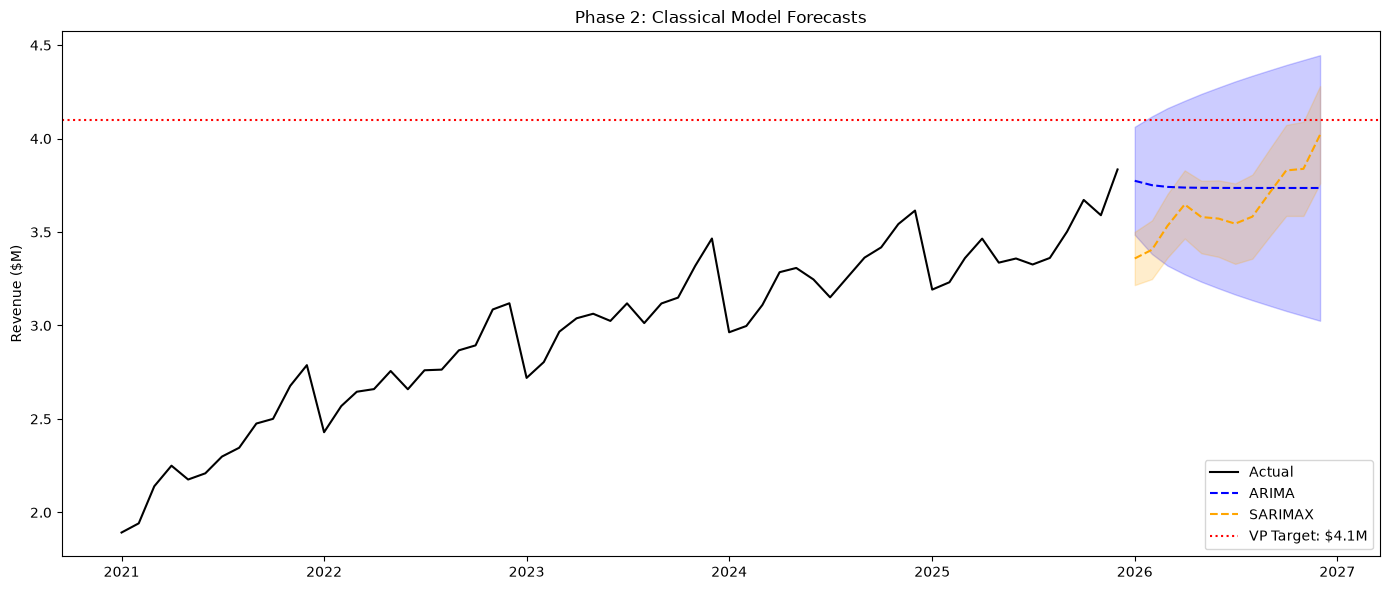

In [21]:
# ---------------------------------------------------------------------------
# Plot both 2026 forecasts with their 95% prediction intervals (shaded bands)
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 6))

# Historical revenue (Jan 2021 - Dec 2025)
ax.plot(revenue.index, revenue / 1e6, 'k-', label='Actual')

# ARIMA forecast (blue) and its 95% interval
ax.plot(fc_index, arima_mean / 1e6, 'b--', label='ARIMA')
ax.fill_between(fc_index, arima_ci.iloc[:, 0] / 1e6, arima_ci.iloc[:, 1] / 1e6,
                color='blue', alpha=0.2)

# SARIMAX forecast (orange) and its 95% interval
ax.plot(fc_index, sarimax_mean / 1e6, 'orange', linestyle='--', label='SARIMAX')
ax.fill_between(fc_index, sarimax_ci.iloc[:, 0] / 1e6, sarimax_ci.iloc[:, 1] / 1e6,
                color='orange', alpha=0.2)

# VP's $4.1M target as a red dotted line
ax.axhline(y=VP_TARGET / 1e6, color='r', linestyle=':', label='VP Target: $4.1M')

ax.set_ylabel('Revenue ($M)')
ax.set_title('Phase 2: Classical Model Forecasts')
ax.legend()
plt.tight_layout()
plt.show()

### Phase 2d Result: December 2026 Forecasts

| Model | Dec 2026 Forecast | 95% Prediction Interval | Gap vs. $4.1M | P(reach $4.1M) |
|---|---|---|---|---|
| ARIMA(1,1,1) | $3.74M | $3.03M – $4.45M | −8.9% | 15.7% |
| **SARIMAX(0,1,1)(0,1,1,12)** | **$4.02M** | **$3.76M – $4.28M** | **−1.9%** | **27.5%** |

**Neither classical model expects revenue to reach $4.1M by December 2026.**

- **SARIMAX (the more trustworthy model)** forecasts **$4.02M**, with a 95% range of $3.76M–$4.28M.
  The $4.1M target lies inside that range but above the centre, giving roughly a **1-in-4 chance**
  (27.5%) of reaching it. The forecast follows the usual yearly pattern: about $3.4M in early 2026,
  rising to its peak in December.
- **ARIMA** forecasts a flat **$3.74M** for every month because it cannot see seasonality. Its interval
  is very wide ($3.03M–$4.45M), and Phase 2c showed its errors are not well-behaved, so its interval
  and probability are less reliable.

**Context on the target:** December is the strongest month of the year. $4.1M is about 7% above
December 2025 ($3.83M), but about 19% above the **average** month of 2025 ($3.44M). The
"18% year-over-year growth" figure therefore only makes sense if the strongest month is compared with an
average month. Even for December specifically, the best classical model says $4.1M is more likely to
be missed than reached.

*The probabilities assume forecast errors follow a normal distribution, which the diagnostics support
for SARIMAX but not for ARIMA.*

---

## Phase 3: Modern Models

We compare three models built with the Darts library:

- **N-BEATS**: a deep-learning model trained only on our revenue history. It uses
  **quantile regression** to learn a low (2.5%), middle (50%) and high (97.5%) estimate,
  which gives a 95% range for each forecast month.
- **Chronos-2**: a pre-trained "foundation model" from Amazon, trained on a large collection of
  time series from many domains. It is used **zero-shot**: it is not trained on our data at all,
  only shown our history at prediction time.
- **Darts ARIMA(2,1,1)**: the required ARIMA(2,1,1) baseline, rebuilt in Darts.

As in Phase 2, models are trained on months before January 2025 and tested on 2025, then
asked to forecast December 2026 from the full 60-month history.

In [22]:
ts = TimeSeries.from_dataframe(
    df.reset_index(), 
    time_col='date', 
    value_cols='revenue', 
    freq='MS'
)

train_ts, test_ts = ts.split_before(pd.Timestamp('2025-01-01'))

print(f"Train: {len(train_ts)} months")
print(f"Test: {len(test_ts)} months")

Train: 48 months
Test: 12 months


In [23]:
# Diagnostic: load the N-BEATS module directly so any real import error is shown
import torch
print("PyTorch:", torch.__version__)

import pytorch_lightning
print("PyTorch Lightning:", pytorch_lightning.__version__)

from darts.models.forecasting.nbeats import NBEATSModel
print("N-BEATS import OK")

# Install PyTorch (CPU version) and the extra packages Darts needs for its
# neural-network models (N-BEATS, Chronos-2), into this notebook's Python
%pip install torch --index-url https://download.pytorch.org/whl/cpu
%pip install pytorch-lightning torchmetrics tensorboardX
%pip install --upgrade pip

PyTorch: 2.15.0+cpu
PyTorch Lightning: 2.5.2
N-BEATS import OK
Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [24]:
# ---------------------------------------------------------------------------
# N-BEATS with quantile regression
# ---------------------------------------------------------------------------
from darts.dataprocessing.transformers import Scaler

# Neural networks train poorly on values in the millions, so we scale revenue
# to the 0-1 range. The scaler learns min/max from the TRAINING data only.
scaler = Scaler()
train_scaled = scaler.fit_transform(train_ts)

nbeats = NBEATSModel(
    input_chunk_length=24,   # look back 24 months (2 full seasonal cycles)
    output_chunk_length=12,  # predict 12 months at once
    n_epochs=200,            # passes over the training data
    # Learn the 2.5%, 50% (median) and 97.5% quantiles -> a 95% range
    likelihood=QuantileRegression([0.025, 0.5, 0.975]),
    random_state=42,         # makes the results reproducible
    # Hide the training progress bars to keep the notebook readable
    pl_trainer_kwargs={"enable_progress_bar": False,
                       "enable_model_summary": False,
                       "logger": False},
)

nbeats.fit(train_scaled)

# Predict the 12 test months (2025) with 100 samples, then convert back to dollars
nbeats_pred = scaler.inverse_transform(nbeats.predict(len(test_ts), num_samples=100))

# Darts compares the median of the samples to the actual values
nbeats_mae = mae(test_ts, nbeats_pred)
nbeats_rmse = rmse(test_ts, nbeats_pred)

print(f"N-BEATS Test MAE: ${nbeats_mae:,.0f}")
print(f"N-BEATS Test RMSE: ${nbeats_rmse:,.0f}")

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
`Trainer.fit` stopped: `max_epochs=200` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


N-BEATS Test MAE: $121,645
N-BEATS Test RMSE: $133,933


In [25]:
# ---------------------------------------------------------------------------
# N-BEATS: 100-sample forecast for 2026
# The model was trained up to Dec 2024. To forecast 2026, we give it the FULL
# history (through Dec 2025) as input with series=..., so its 12-month forecast
# covers Jan - Dec 2026.
# ---------------------------------------------------------------------------
full_scaled = scaler.transform(ts)
nbeats_forecast_100samp = scaler.inverse_transform(
    nbeats.predict(HORIZON, series=full_scaled, num_samples=100)
)

# all_values() has shape (months, components, samples); take all 100 samples
# for the last month (December 2026). Note: .values() would only return sample 1.
dec_samples = nbeats_forecast_100samp.all_values()[-1, 0, :]

nbeats_dec_2026 = np.median(dec_samples)                         # point forecast
nbeats_lower, nbeats_upper = np.percentile(dec_samples, [2.5, 97.5])  # 95% range
nbeats_prob = np.mean(dec_samples >= VP_TARGET)                  # share reaching $4.1M

print(f"Number of samples: {len(dec_samples)}")
print(f"N-BEATS Dec 2026 forecast (median): ${nbeats_dec_2026/1e6:.2f}M")
print(f"95% interval: [${nbeats_lower/1e6:.2f}M, ${nbeats_upper/1e6:.2f}M]")
print(f"Gap vs. $4.1M target: {(nbeats_dec_2026 - VP_TARGET) / VP_TARGET:+.1%}")
print(f"Samples reaching $4.1M: {nbeats_prob:.0%}")

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Number of samples: 100
N-BEATS Dec 2026 forecast (median): $3.79M
95% interval: [$3.55M, $3.95M]
Gap vs. $4.1M target: -7.5%
Samples reaching $4.1M: 0%


In [26]:
# ---------------------------------------------------------------------------
# Chronos-2 zero-shot forecasting
# A pre-trained foundation model: it is NOT trained on our data. fit() only
# prepares the model; the forecast comes from patterns learned during
# Amazon's pre-training on many other time series.
# ---------------------------------------------------------------------------
from darts.models import Chronos2Model

REQUIRED_MODEL = "amazon/chronos-bolt-small"   # model name given in the project rubric
FALLBACK_MODEL = "autogluon/chronos-2-small"   # small Chronos-2 model supported by Darts

# Look-back window: fit() needs input_chunk_length + output_chunk_length months
# of training data. With 48 training months and a 12-month output, the longest
# possible look-back is 36 months (36 + 12 = 48).
CHRONOS_INPUT_LENGTH = 36

# Chronos-Bolt uses a different architecture from Chronos-2, so Darts'
# Chronos2Model cannot load it. We try the required model first and fall back
# to the small Chronos-2 model if it fails.
try:
    chronos = Chronos2Model(
        input_chunk_length=CHRONOS_INPUT_LENGTH,  # months of history the model sees
        output_chunk_length=HORIZON,              # forecast 12 months at once
        hub_model_name=REQUIRED_MODEL,
        pl_trainer_kwargs={"enable_progress_bar": False},
    )
    chronos_model_used = REQUIRED_MODEL
except Exception as e:
    print(f"'{REQUIRED_MODEL}' could not be loaded by Chronos2Model ({type(e).__name__}: {e}).")
    print(f"Using '{FALLBACK_MODEL}' instead.\n")
    chronos = Chronos2Model(
        input_chunk_length=CHRONOS_INPUT_LENGTH,
        output_chunk_length=HORIZON,
        hub_model_name=FALLBACK_MODEL,
        pl_trainer_kwargs={"enable_progress_bar": False},
    )
    chronos_model_used = FALLBACK_MODEL

# "Fit" on the training set (zero-shot: no weights are changed)
chronos.fit(train_ts)

# Test accuracy on 2025, for comparison with the other models
chronos_test_pred = chronos.predict(len(test_ts))
chronos_mae = mae(test_ts, chronos_test_pred)
print(f"Chronos model: {chronos_model_used}")
print(f"Chronos-2 Test MAE: ${chronos_mae:,.0f}")

# Forecast 2026 by giving the model the full history through Dec 2025
chronos_forecast = chronos.predict(HORIZON, series=ts)
chronos_dec_2026 = chronos_forecast.values()[-1][0]   # last month, first component

print(f"Chronos-2 Dec 2026: ${chronos_dec_2026/1e6:.2f}M")
print(f"Gap vs. $4.1M target: {(chronos_dec_2026 - VP_TARGET) / VP_TARGET:+.1%}")

'amazon/chronos-bolt-small' could not be loaded by Chronos2Model (KeyError: 'output_patch_size').
Using 'autogluon/chronos-2-small' instead.



GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Chronos model: autogluon/chronos-2-small
Chronos-2 Test MAE: $168,433
Chronos-2 Dec 2026: $3.81M
Gap vs. $4.1M target: -7.1%


In [27]:
# ---------------------------------------------------------------------------
# ARIMA(2,1,1) baseline using Darts
# Same model order as the required ARIMA in Phase 2a, built with the Darts
# library so it can be compared directly with N-BEATS and Chronos-2.
# ---------------------------------------------------------------------------

# 1) Test accuracy: train through Dec 2024, forecast 2025
darts_arima = DartsARIMA(p=2, d=1, q=1)
darts_arima.fit(train_ts)
darts_arima_mae = mae(test_ts, darts_arima.predict(len(test_ts)))
print(f"DartsARIMA(2,1,1) Test MAE: ${darts_arima_mae:,.0f}")

# 2) Refit on all 60 months and forecast Jan - Dec 2026
darts_arima.fit(ts)
darts_arima_forecast = darts_arima.predict(HORIZON)
darts_arima_dec_2026 = darts_arima_forecast.values()[-1][0]   # December 2026

print(f"DartsARIMA(2,1,1) Dec 2026: ${darts_arima_dec_2026/1e6:.2f}M")
print(f"Gap vs. $4.1M target: {(darts_arima_dec_2026 - VP_TARGET) / VP_TARGET:+.1%}")

DartsARIMA(2,1,1) Test MAE: $360,236
DartsARIMA(2,1,1) Dec 2026: $4.17M
Gap vs. $4.1M target: +1.8%


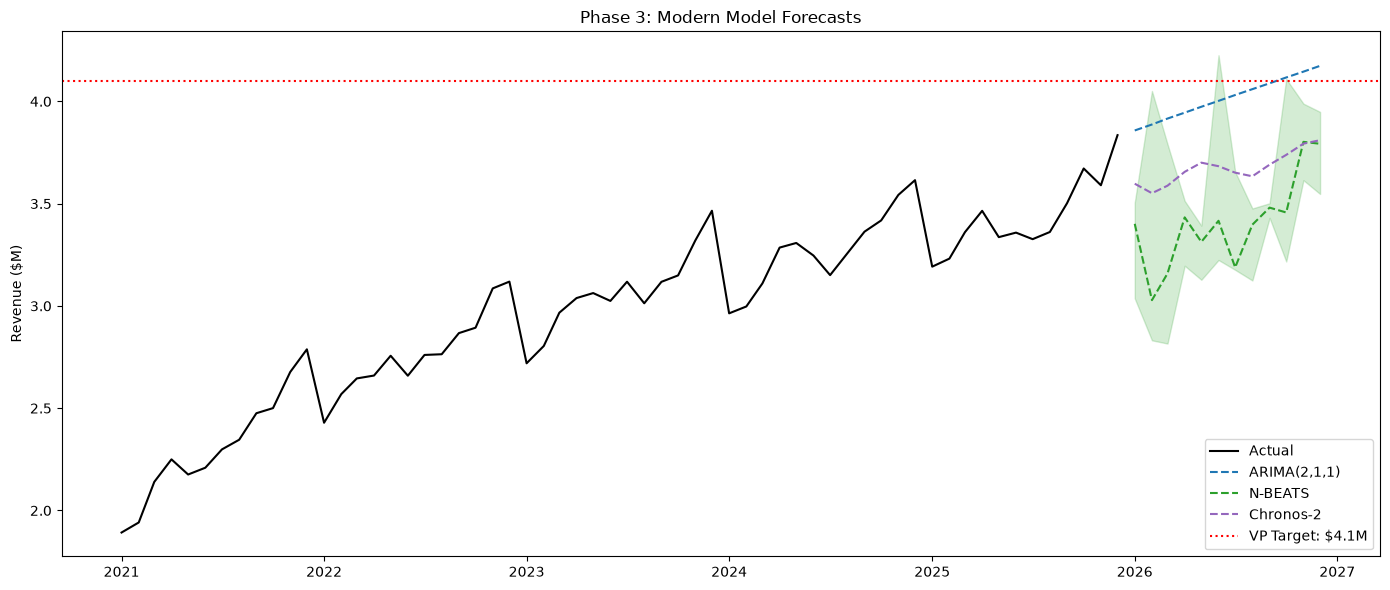

In [28]:
# ---------------------------------------------------------------------------
# Plot the history and the 2026 forecasts of all three Darts models
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 6))

# Historical revenue
ax.plot(revenue.index, revenue / 1e6, 'k-', label='Actual')

# Forecast months: Jan - Dec 2026
nbeats_index = pd.date_range('2026-01-01', periods=HORIZON, freq='MS')

# Darts ARIMA(2,1,1)
ax.plot(nbeats_index, darts_arima_forecast.values().ravel() / 1e6,
        '--', color='tab:blue', label='ARIMA(2,1,1)')

# N-BEATS: median of the 100 samples, with the 95% range shaded
nbeats_median = nbeats_forecast_100samp.quantile(0.5).values().ravel()
nbeats_low = nbeats_forecast_100samp.quantile(0.025).values().ravel()
nbeats_high = nbeats_forecast_100samp.quantile(0.975).values().ravel()
ax.plot(nbeats_index, nbeats_median / 1e6, '--', color='tab:green', label='N-BEATS')
ax.fill_between(nbeats_index, nbeats_low / 1e6, nbeats_high / 1e6,
                color='tab:green', alpha=0.2)

# Chronos-2
ax.plot(nbeats_index, chronos_forecast.values().ravel() / 1e6,
        '--', color='tab:purple', label='Chronos-2')

# VP's $4.1M target
ax.axhline(y=VP_TARGET / 1e6, color='r', linestyle=':', label='VP Target: $4.1M')

ax.set_ylabel('Revenue ($M)')
ax.set_title('Phase 3: Modern Model Forecasts')
ax.legend()
plt.tight_layout()
plt.show()

In [29]:
# ---------------------------------------------------------------------------
# Phase 3 summary: test accuracy and December 2026 forecast for each model
# ---------------------------------------------------------------------------
phase3_summary = pd.DataFrame({
    'Model': ['N-BEATS', f'Chronos-2 ({chronos_model_used})', 'Darts ARIMA(2,1,1)'],
    'Test MAE ($)': [nbeats_mae, chronos_mae, darts_arima_mae],
    'Dec 2026 Forecast ($M)': [nbeats_dec_2026 / 1e6,
                               chronos_dec_2026 / 1e6,
                               darts_arima_dec_2026 / 1e6],
    # Only N-BEATS produces a 95% range here (from its 100 samples)
    '95% Lower ($M)': [nbeats_lower / 1e6, np.nan, np.nan],
    '95% Upper ($M)': [nbeats_upper / 1e6, np.nan, np.nan],
})
# Gap vs. the VP's target as a percentage (negative = below target)
phase3_summary['Gap vs $4.1M'] = (
    (phase3_summary['Dec 2026 Forecast ($M)'] * 1e6 - VP_TARGET) / VP_TARGET
)

print(phase3_summary.to_string(index=False, formatters={
    'Test MAE ($)': '{:,.0f}'.format,
    'Dec 2026 Forecast ($M)': '{:.2f}'.format,
    '95% Lower ($M)': '{:.2f}'.format,
    '95% Upper ($M)': '{:.2f}'.format,
    'Gap vs $4.1M': '{:+.1%}'.format,
}))
print(f"\nN-BEATS samples reaching $4.1M: {nbeats_prob:.0%}")

                                Model Test MAE ($) Dec 2026 Forecast ($M) 95% Lower ($M) 95% Upper ($M) Gap vs $4.1M
                              N-BEATS      121,645                   3.79           3.55           3.95        -7.5%
Chronos-2 (autogluon/chronos-2-small)      168,433                   3.81            NaN            NaN        -7.1%
                   Darts ARIMA(2,1,1)      360,236                   4.17            NaN            NaN        +1.8%

N-BEATS samples reaching $4.1M: 0%


---

## Phase 4: Comparison and Recommendation

In [32]:
comparison_data = {
    'Model': ['Naive', '6MA', '12MA', 'Trend', 'ARIMA', 'SARIMAX', 'N-BEATS', 'Chronos-2'],
    'Dec 2026 Forecast': [
        naive_fc.iloc[-1],
        ma6_fc.iloc[-1],
        ma12_fc.iloc[-1],
        trend_fc.iloc[-1],
        arima_dec_2026,
        sarimax_dec_2026,
        nbeats_dec_2026,
        chronos_dec_2026
    ],
    '95% CI Lower': [
        np.nan, np.nan, np.nan, np.nan,
        arima_lower,
        sarimax_lower,
        np.nan, np.nan
    ],
    '95% CI Upper': [
        np.nan, np.nan, np.nan, np.nan,
        arima_upper,
        sarimax_upper,
        np.nan, np.nan
    ],
    'Test MAE': [
        np.nan, np.nan, np.nan, np.nan,
        arima_mae,
        sarimax_mae,
        nbeats_mae,
        np.nan
    ],
    'P(Reach $4.1M)': [
        np.nan, np.nan, np.nan, np.nan,
        arima_prob,
        sarimax_prob,
        np.nan, np.nan
    ]
}

comparison_df = pd.DataFrame(comparison_data)
comparison_df['Dec 2026 Forecast'] = comparison_df['Dec 2026 Forecast'] / 1e6
comparison_df['95% CI Lower'] = comparison_df['95% CI Lower'] / 1e6
comparison_df['95% CI Upper'] = comparison_df['95% CI Upper'] / 1e6

print(comparison_df.to_string(index=False))

    Model  Dec 2026 Forecast  95% CI Lower  95% CI Upper      Test MAE  P(Reach $4.1M)
    Naive           3.834907           NaN           NaN           NaN             NaN
      6MA           3.547799           NaN           NaN           NaN             NaN
     12MA           3.435851           NaN           NaN           NaN             NaN
    Trend           3.975722           NaN           NaN           NaN             NaN
    ARIMA           3.735763      3.025271      4.446254 197741.712754        0.157496
  SARIMAX           4.020657      3.760219      4.281096 114113.007241        0.275216
  N-BEATS           3.792743           NaN           NaN 121645.400295             NaN
Chronos-2           3.810293           NaN           NaN           NaN             NaN


### Written Recommendation

Write a 500–1000 word stakeholder-ready recommendation addressing:

1. **What is the realistic range for December 2026 revenue?**
   - Based on model forecasts and prediction intervals
   - Consider the spread across different approaches

2. **What should the company plan for?**
   - Provide a specific target or range based on your analysis
   - Explain the gap between models and the VP's original $4.1M target
   - Discuss probability of achieving different revenue levels

3. **Which forecasting approach would you recommend for ongoing use, and why?**
   - Compare accuracy, interpretability, and practical considerations
   - Consider maintenance requirements and stakeholder understanding
   - Recommend a specific approach with justification

**YOUR WRITTEN RECOMMENDATION (500–1000 words):**

[Write your recommendation here...]